---
title: "Panel 1.10.0 Release"
date: "2026-10-14"
description: "Release announcement for Panel 1.10"
author: "Philipp Rudiger"
categories: [release, panel]
image: "images/collage_1.10.png"
aliases:
  - ../../panel_1.10.html
format:
  html:
    include-in-header:
      text: <link rel="stylesheet" href="https://fonts.googleapis.com/icon?family=Material+Icons">
---

In [1]:
#| echo: false
import panel as pn

pn.extension(inline=False)

<img src="./images/collage_1.10.png" width="100%"></img>

## What is Panel?

[Panel](https://panel.holoviz.org/) is an open-source Python library that allows you to **easily create powerful tools, dashboards, and complex applications entirely in Python**. With its "batteries-included" philosophy, Panel brings the full PyData ecosystem, advanced data tables, and much more to your fingertips. It offers both high-level reactive APIs and lower-level callback-based APIs, enabling you to quickly build exploratory applications or develop complex, multi-page apps with rich interactivity. As a member of the [HoloViz](https://holoviz.org) ecosystem, Panel provides seamless integration with a suite of tools designed for data exploration.

## New Release!

We are excited to announce the 1.10.0 release of Panel! This is the biggest step towards Panel 2.0 so far. It changes how you build Panel apps, with a new Material UI based component namespace, and where you can deploy them, with a native ASGI server. Here's a high-level overview of the highlights:

- [**`panel.ui`**](#panel.ui): A single component namespace that combines the Material UI components from `panel-material-ui` with the classic Panel components that have no Material equivalent, plus a `panel migrate` command to move existing apps over.
- [**Native ASGI server support**](#native-asgi-server-support): Panel now ships its own ASGI application. `panel serve --server fastapi` and `--server asgi` run apps on uvicorn, and the FastAPI and Django integrations no longer depend on `bokeh-fastapi`, `bokeh-django` or Django Channels.
- [**Themed server pages and a new admin dashboard**](#server-pages-and-the-admin-dashboard): The index, login and error pages match `panel.ui` and can be branded with `pn.config.page_config`, and the `/admin` dashboard has been rebuilt and can be secured on its own.
- [**On-demand resource loading**](#on-demand-resource-loading): Components fetch the JavaScript libraries they need the first time they render, so `pn.extension('tabulator')` is now an optional preloading hint.
- [**Performance**](#performance): `JSComponent` and `ReactComponent` rendering no longer scales quadratically with the number of components, LLM-style streaming into `Markdown` has a constant cost per token, and `Tabulator` no longer pulls in the 500 KB bokeh-tables bundle.

Panel 1.10 requires Bokeh 3.10 and Python 3.12 or later, and adds support for Python 3.15.

Many thanks to the contributors to this release: [@philippjfr](https://github.com/philippjfr), [@hoxbro](https://github.com/hoxbro), [@chiruu12](https://github.com/chiruu12), [@MohammadHijjawi97](https://github.com/MohammadHijjawi97), [@ebarkhordar](https://github.com/ebarkhordar), [@Kayvan-Zahiri](https://github.com/Kayvan-Zahiri), [@ghostiee-11](https://github.com/ghostiee-11), [@Azaya89](https://github.com/Azaya89), [@rimsha152007-dotcom](https://github.com/rimsha152007-dotcom), [@EltonChang1](https://github.com/EltonChang1), [@Bortlesboat](https://github.com/Bortlesboat), [@ATL2001](https://github.com/ATL2001), [@ZainnQureshii](https://github.com/ZainnQureshii), [@vignesh-chaturvedi](https://github.com/vignesh-chaturvedi), [@IDavinciCode](https://github.com/IDavinciCode), [@mvanhorn](https://github.com/mvanhorn), [@SatvikMishra08](https://github.com/SatvikMishra08), [@YashAnand69](https://github.com/YashAnand69), [@Cherith1222](https://github.com/Cherith1222), [@anshurajbisoyi98-ctrl](https://github.com/anshurajbisoyi98-ctrl) and [@Coderambling](https://github.com/Coderambling).

<hr>

If you're using [Anaconda](https://www.anaconda.com/downloads), you can install the latest version of Panel with `conda install panel`. If you prefer pip, use `pip install panel`.

<hr>

## `panel.ui`

Over the past year [panel-material-ui](https://github.com/panel-extensions/panel-material-ui) has grown into a complete Material UI based component library for Panel, and in Panel 1.9 we aligned the classic widget API with it by introducing `label`, `color` and `variant`. Panel 1.10 completes the next step: the Material components are now part of Panel itself under `panel.ui` ([#8752](https://github.com/holoviz/panel/pull/8752)).


`panel.ui` exports every component it provides both flat and through `widgets`, `layout`, `pane`, `chat`, `indicators`, `template` and `wrappers` submodules, so `pn.ui.Button` and `pn.ui.widgets.Button` are the same class. Where Material UI has an equivalent, you get the Material component. Where it does not, such as `Tabulator`, `CodeEditor`, `Perspective`, `Plotly`, `HoloViews` or `Terminal`, `panel.ui` re-exports the classic component unchanged:

In [2]:
#| echo: false
import pandas as pd

fill = dict(sizing_mode='stretch_width')

def group(*widgets):
    return pn.ui.Column(*widgets, width=300, margin=(16, 20, 0, 0))

df = pd.DataFrame({'model': ['xgb', 'rf', 'mlp', 'svm'], 'auc': [0.93, 0.91, 0.89, 0.85], 'time (s)': [12, 18, 41, 7]})

inputs = pn.ui.Row(
    group(
        pn.ui.TextInput(label='Name', value='Panel 1.10', **fill),
        pn.ui.TextAreaInput(label='Notes', value='Release notes draft', rows=3, **fill),
        pn.ui.PasswordInput(label='Token', value='secret', **fill),
    ),
    group(
        pn.ui.DatePicker(label='Release', value=pd.Timestamp('2026-10-14').date(), **fill),
        pn.ui.DatetimePicker(label='Deadline', value=pd.Timestamp('2026-11-01 09:30'), **fill),
        pn.ui.ColorPicker(label='Accent', value='#1976d2', **fill),
        pn.ui.IntInput(label='Workers', value=4, **fill),
    ),
)
selection = pn.ui.Row(
    group(
        pn.ui.Select(label='Colormap', options=['viridis', 'magma', 'cividis'], value='magma', **fill),
        pn.ui.MultiChoice(label='Regions', options=['EU', 'US', 'APAC'], value=['EU', 'APAC'], **fill),
        pn.ui.AutocompleteInput(label='Station', options=['Alpha', 'Bravo', 'Charlie'], value='Bravo', **fill),
    ),
    group(
        pn.ui.RadioButtonGroup(options=['Day', 'Week', 'Month'], value='Week', **fill),
        pn.ui.ToggleGroup(options=['Bold', 'Italic', 'Code'], value=['Bold'], **fill),
        pn.ui.CheckBoxGroup(options=['Smooth', 'Normalize', 'Log scale'], value=['Smooth']),
    ),
)
sliders = pn.ui.Row(
    group(
        pn.ui.FloatSlider(label='Threshold', start=0, end=1, value=0.6, **fill),
        pn.ui.RangeSlider(label='Window', start=0, end=100, value=(20, 70), **fill),
        pn.ui.DateRangeSlider(label='Period', start=pd.Timestamp('2025-01-01'), end=pd.Timestamp('2026-01-01'),
                              value=(pd.Timestamp('2025-03-01'), pd.Timestamp('2025-09-01')), **fill),
    ),
    group(
        pn.ui.EditableRangeSlider(label='Budget', start=0, end=1000, value=(200, 650), **fill),
        pn.ui.Switch(label='Live', value=True),
        pn.ui.Rating(value=4, size='small'),
    ),
)
feedback = pn.ui.Row(
    group(
        pn.ui.Row(
            pn.ui.Button(label='Run', icon='play_arrow', color='primary'),
            pn.ui.Button(label='Save', icon='save', variant='outlined'),
            pn.ui.Button(label='Delete', icon='delete', color='error', variant='outlined'),
        ),
        pn.ui.Progress(value=64, label='Build', **fill),
        pn.ui.Row(pn.ui.Chip(label='stable', color='success'), pn.ui.Chip(label='beta', color='warning')),
    ),
    group(
        pn.ui.Alert('Deployment finished without warnings.', severity='success', **fill),
        pn.ui.Alert('Disk usage is at 91%.', severity='warning', **fill),
    ),
)
table = pn.ui.Tabulator(df, show_index=False, **fill)
editor = pn.ui.CodeEditor(value="import panel as pn\n\npn.ui.Button(label='Run')", language='python', height=200, **fill)

def show_selected(menu, pages):
    content = [obj for _, obj in pages.values()]
    for i, obj in enumerate(content):
        obj.visible = i == 0
        menu.jslink(obj, code={'active': f'target.visible = source.active[0] === {i}'})
    return content


Page(config=_base_config, design=<class 'panel.ui.theme.Mat..., height=440, logo='images/panel_logo.png', main=[Row, Row, Row, ...], meta=Meta, sidebar=[MenuList], sidebar_width=140, sizing_mode='stretch_width')
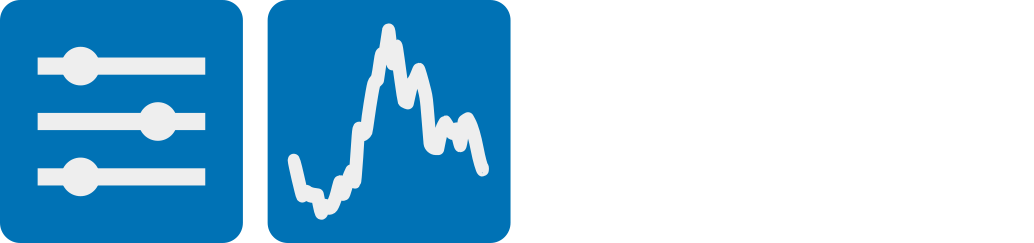

In [3]:
pages = {
    'Inputs': ('edit_note', inputs),
    'Selection': ('checklist', selection),
    'Sliders': ('tune', sliders),
    'Feedback': ('notifications', feedback),
    'Data': ('table_chart', table),
    'Code': ('code', editor),
}
menu = pn.ui.MenuList(
    items=[{'label': name, 'icon': icon} for name, (icon, _) in pages.items()],
    active=(0,), sizing_mode='stretch_width',
)

pn.ui.Page(
    logo='images/panel_logo.png', sidebar=[menu], sidebar_width=140,
    main=show_selected(menu, pages), height=440,
).servable()


In [4]:
#| echo: false
pn.config.sizing_mode = None

To see what a complete `pn.ui` application looks like, here is the [Storm Surge Studio](https://panel.holoviz.org/gallery/storm_surge_studio.html), one of the new apps in the gallery. It is an interactive coastal atlas for a synthetic storm, built from a `pn.ui.Page` with Material widgets in the sidebar, `Typography`, `Paper` and `Grid` layouts, and three Bokeh figures that are updated in place as you change the scenario.

The app below is rendered live in this post. There is no Python process behind this page, so the controls will not recompute the flood, but everything that runs in the browser works: open the menu in the top left to see the controls, and hover over the map, the coastal profile and the timeline. To run the full app yourself, download the [notebook](https://github.com/holoviz/panel/blob/main/examples/gallery/storm_surge_studio.ipynb) and run `panel serve storm_surge_studio.ipynb`.

An app no longer has to decide, component by component, whether to import from `pn.widgets` or from `panel_material_ui`. Every name is an explicit import, so Pyright, mypy and IDE autocompletion resolve `pn.ui.Button` to a real class, and together with the typing work in Panel 1.9 you get parameter completion and type checking for the whole namespace.

The classic components re-exported under `panel.ui` also adopt the Material look. Under the Material UI design `Tabulator`, `CodeEditor`, `JSONEditor`, `Markdown`, `Terminal` and others get stylesheets mapped onto the MUI palette, and the `Dial`, `LinearGauge` and `Gauge` indicators derive their label, needle and track colors from the theme, so they follow light and dark mode instead of rendering black on white. `Modal`, `WidgetBox` and `Debugger`, which had no counterpart in `panel-material-ui`, have new Material implementations that keep the classic API.

### Opt-in, and the classic API stays

`panel.ui` is opt-in. `import panel` on its own does not import `panel-material-ui` or change the design, and `pn.widgets`, `pn.layout`, `pn.pane` and the classic templates continue to work as before. `pn.ui` is resolved lazily the first time you access it, and at that point Panel selects the `MaterialUIDesign` unless you have already chosen a design. You can also select it explicitly with `pn.extension(design='material-ui')`.

Material and classic components can be mixed in one app, so you can migrate incrementally.

### `Page` as the default template

`pn.ui.Page` is now also available as a template name, so apps written in the `.servable(target=...)` style can use it without constructing it explicitly ([#8808](https://github.com/holoviz/panel/pull/8808)):

```python
import panel as pn

pn.extension(template='page')

slider = pn.ui.IntSlider(label='Stars', start=0, end=10, value=3)

slider.servable(target='sidebar')
pn.panel(pn.bind(lambda n: '⭐' * n, slider)).servable(target='main')
```

The `main`, `sidebar`, `header` and `contextbar` areas are supported, and an unknown `target` now raises an error instead of being silently dropped. The getting started, core concepts and templates guides have been rewritten around `Page`.

### Generated widgets follow the design

Panel generates widgets for you in several places: `pn.Param` for Parameterized classes, `pn.interact`, and the widgets created for the dimensions of a HoloViews `HoloMap` or `DynamicMap`. Previously `panel-material-ui` had to monkeypatch Panel's internal mappings to make those produce Material widgets. Designs can now declare a `component_mapping` and `widget_mapping`, so under the Material UI design a `param.Number` becomes a Material `FloatSlider` and a `param.Selector` becomes a Material `Select`:

In [5]:
import param

class Settings(param.Parameterized):
    threshold = param.Number(default=0.5, bounds=(0, 1))
    mode = param.Selector(objects=['fast', 'accurate'])

pn.ui.Card(pn.Param(Settings(), show_name=False), title='Settings')

Card(_headers=[Str], _names=['Settings'], design=<class 'panel.ui.theme.Mat..., objects=[Param], title='Settings')

An explicit `widget_type` always takes precedence over the mapping.

The same design hooks cover the loading spinner and the page template. A design can declare its own spinner and template variables, and the loading overlay now follows the theme's background color, so dark themes no longer flash white while a component loads.

### Migrating with `panel migrate`

To make moving existing apps easier, Panel 1.10 ships a codemod. Install the optional dependency and point it at a file or directory:

```bash
pip install 'panel[migrate]'
panel migrate my_app/         # report what would change
panel migrate --diff my_app/  # also print a unified diff
panel migrate --fix my_app/   # write the changes
```

Without `--fix` the command exits with a non-zero status if any file would change, so you can also use it as a CI check. Given a classic app like this:

```python
import panel as pn

pn.extension(design='bootstrap')

button = pn.widgets.Button(name='Run', button_type='primary')
slider = pn.widgets.IntSlider(name='Stars', start=0, end=10, value=3)

pn.template.FastListTemplate(
    title='Stars',
    sidebar=[button],
    main=[slider.rx() * '⭐'],
).servable()
```

`panel migrate --diff` proposes:

```diff
-pn.extension(design='bootstrap')
+pn.extension()

-button = pn.widgets.Button(name='Run', button_type='primary')
-slider = pn.widgets.IntSlider(name='Stars', start=0, end=10, value=3)
+button = pn.ui.Button(label='Run', color='primary')
+slider = pn.ui.IntSlider(label='Stars', start=0, end=10, value=3)

-pn.template.FastListTemplate(
+pn.ui.Page(
```

The tool rewrites classic imports to `pn.ui`, `name=` to `label=`, `button_type` and `button_style` to `color` and `variant`, `MenuButton(split=True)` to `SplitButton`, `size` to `icon_size` on `ToggleIcon` and `ButtonIcon`, and compatible classic templates to `pn.ui.Page`. Imports from `panel_material_ui` are rewritten to the same classes under `pn.ui`. Anything it cannot confirm, such as unsupported arguments, argument unpacking or template options without a `Page` equivalent, is left untouched and listed for manual review.

The codemod only changes Python source. Custom CSS that targets classic class names, custom `Design` subclasses, Jinja templates and `jslink`/`jscallback` code referencing classic model properties need to be updated by hand, and a handful of components differ in their defaults: a Material `Button` defaults to `color='primary'` and `variant='contained'`, for example. The [upgrade guide](https://panel.holoviz.org/upgrade.html) lists every parameter and default that differs between the classic and `panel.ui` components.

### Documentation and gallery

The Panel documentation has a new homepage, is now versioned, and uses `pn.ui` throughout. The Component Gallery is generated from the `panel-material-ui` reference notebooks, the classic reference has moved to its own section, and each replaced component links back to its classic page.

The [app gallery](https://panel.holoviz.org/gallery/index.html) has been modernized as well, and has a few new additions, including a [Gaia million star atlas](https://panel.holoviz.org/gallery/gaia_million_star_atlas.html) that renders 1.25 million real stars across three linked views, a [model serving monitor](https://panel.holoviz.org/gallery/model_serving_monitor.html) that simulates traffic surges, drift and outages against live SLO alerts, and a [storm surge studio](https://panel.holoviz.org/gallery/storm_surge_studio.html) for exploring coastal flooding scenarios.

### What comes next

For now the Material components are implemented in `panel-material-ui`, which Panel depends on and checks against a supported version range at import. In Panel 2.0 the implementation moves into Panel itself. The imports under `panel.ui` will stay the same, so code written against `pn.ui` today will not need to change.

## Native ASGI Server Support

Panel apps have always run on the Bokeh server, which is built on Tornado. For many deployments that is fine, but a growing number of teams want to serve Panel apps from an existing FastAPI or Django project, or run them on the same ASGI infrastructure as the rest of their Python services.

Panel has supported this for a while, but through workarounds. The FastAPI integration added in Panel 1.5 was built on the external `bokeh-fastapi` package and needed several monkeypatches into its internals, and the Django integration relied on `bokeh-django` and Django Channels, with Panel patching their consumers. Bokeh 3.10 split the Bokeh server into a transport-independent core and added a framework-neutral ASGI application. Panel 1.10 builds its own ASGI application on top of that, and uses it for `panel serve`, FastAPI and Django alike ([#8722](https://github.com/holoviz/panel/pull/8722)).

### `panel serve --server`

`panel serve` has a new `--server` option:

```bash
pip install uvicorn fastapi
panel serve app.py --server fastapi
```

The choices are `tornado` (the default, unchanged), `asgi`, which runs Panel's ASGI application on uvicorn without importing FastAPI, and `fastapi`, which mounts the same application on a FastAPI app. The ASGI implementations support the same options as the Tornado server, including the admin dashboard, `--static-dirs`, `--index`, `--liveness`, wildcard routes, TLS and all of the authentication options. A few options that are implemented as Tornado request handlers (`--rest-provider`, `--enable-xsrf-cookies` and `--num-procs`) fail with an error naming the option. Session info, which used to be served by the `param` REST provider, now comes from a built-in `/session_info` endpoint on every server ([#8828](https://github.com/holoviz/panel/pull/8828)).

Custom endpoints declared with `--plugins` work on `--server fastapi`, where the plugin module declares a FastAPI `APIRouter` in a `ROUTER` variable instead of a list of Tornado handlers:

```python
# plugin.py
from fastapi import APIRouter, HTTPException

ROUTER = APIRouter()

@ROUTER.get('/sum')
def sum_values(a: int = 0, b: int = 0):
    if a < 0 or b < 0:
        raise HTTPException(400, 'Arguments must be positive.')
    return a + b
```

```bash
panel serve app.py --server fastapi --plugins plugin
```

A module can declare both `ROUTES` and `ROUTER` and be served on either implementation.

To run the ASGI application under a server of your choice, or mount it in another ASGI framework such as Starlette, build it with `build_asgi_app`:

```python
import panel as pn

from panel.io.asgi import build_asgi_app

def stars():
    slider = pn.ui.IntSlider(label='Stars', start=0, end=10, value=3)
    return slider.rx() * '⭐'

app = build_asgi_app({'/stars': stars})
```

```bash
uvicorn app:app --workers 4
```

The [Serving on ASGI](https://panel.holoviz.org/how_to/server/asgi.html) guide covers the supported options, mounting, multiple workers and running behind a proxy.

### FastAPI

The public API of `panel.io.fastapi` is unchanged, but `bokeh-fastapi` is no longer needed and `pip install panel[fastapi]` no longer installs it:

```python
import panel as pn

from fastapi import FastAPI
from panel.io.fastapi import add_application

app = FastAPI()

@app.get("/")
async def read_root():
    return {"Hello": "World"}

@add_application('/panel', app=app, title='My Panel App')
def create_panel_app():
    slider = pn.ui.IntSlider(label='Slider', start=0, end=10, value=3)
    return slider.rx() * '⭐'
```

Panel now installs itself as a middleware that claims only the paths it owns and hands everything else to FastAPI, so it no longer matters whether you call `add_applications` before or after declaring your own routes, and you can call it more than once. The integration serves the same endpoints as `panel serve`, including the `autoload.js`, `metadata` and static resource endpoints that `bokeh-fastapi` could not serve, as well as `/liveness`, `static_dirs` and the index page. Wildcard routes populate `pn.state.route_params`, and a `prefix` argument serves all apps below a common path.

### Authentication on every server

Authentication is configured with the same arguments everywhere. `basic_auth`, `oauth_provider` and the related options are accepted by `panel serve`, `pn.serve`, `panel.io.fastapi.add_applications` and `panel.io.django.get_asgi_application`:

```python
add_applications(
    {"/panel_app": create_panel_app},
    app=app,
    oauth_provider='azure',
    oauth_key='...',
    oauth_secret='...',
    oauth_encryption_key='...',
    cookie_secret='...',
)
```

On the ASGI server Panel runs its existing OAuth handlers unmodified, so all of the supported providers, PKCE and token refresh behave the same as on Tornado. Session cookies are signed the same way on both servers, so with a shared `cookie_secret` and `oauth_encryption_key` a user logged in on a Tornado process is accepted by an ASGI process and vice versa. You can run both behind one load balancer, or move a deployment from one to the other without logging everyone out.

### Django

The Django integration has been rewritten around Django's own ASGI application. Panel serves the app documents, their websockets and its static resources, and hands every other request to Django, including your views, the admin and your own static files. `channels`, `daphne` and `bokeh-django` are no longer involved:

```python
# project/asgi.py
import django

django.setup()

import myapp.pn_app as pn_app

from panel.io.django import autoload, get_asgi_application

application = get_asgi_application([
    autoload('myapp', pn_app.app),
])
```

With `panel.io.django` added to `INSTALLED_APPS`, `python manage.py runserver` serves the project with uvicorn during development, and in production you run it with any ASGI server, e.g. `uvicorn project.asgi:application`. Existing projects keep the `document`, `autoload`, `directory`, `with_request` and `with_url_args` helpers; the `routing.py` module, the `bokeh_apps` URL patterns and `STATICFILES_DIRS = [bokehjsdir()]` can be deleted. The [Django how-to guide](https://panel.holoviz.org/how_to/integrations/Django.html) has a step-by-step section on migrating from `bokeh-django`.

## Server Pages and the Admin Dashboard

Besides your applications, the Panel server renders a few pages of its own: the index page listing the applications, the login and logout pages of the basic auth provider, and the error pages. These have been restyled to match `panel.ui`, share one stylesheet that follows the operating system's dark mode, and the index page search now also matches paths ([#8802](https://github.com/holoviz/panel/pull/8802)).

They can also be branded. If your apps already set class defaults on `pn.ui.Page`, such as a `theme_config`, `logo` or `title`, in a module passed to `--setup`, the server pages pick those up automatically. To configure them separately, pass a dictionary to `pn.config.page_config`, or a JSON string or file to `panel serve --page-config`:

```json
{
  "title": "Acme Analytics",
  "logo": {"light": "assets/logo.svg", "dark": "assets/logo_dark.svg"},
  "theme_config": {
    "palette": {"primary": {"main": "#00695c"}},
    "shape": {"borderRadius": 12}
  }
}
```

```bash
panel serve apps/*.py --page-config page_config.json
```

<img src="./images/index_page_config.png" width="100%"></img>

The `/admin` dashboard has been rebuilt with `panel.ui` as well ([#8805](https://github.com/holoviz/panel/pull/8805)). It is now a `Page` with sidebar navigation between the overview, timeline, user profiling and log pages, which are only built when you open them. The log view gained per-session filters, case-insensitive text filtering and buttons to clear the filters and download the log, and the dashboard follows the same `page_config` theming as the other server pages.

<img src="./images/admin.png" width="100%"></img>

Previously the admin dashboard was only as protected as the apps it monitored. It can now be secured on its own: `--admin-password` (or `PANEL_ADMIN_PASSWORD`) puts only the admin endpoint behind a login page, and `--admin-users` (or `PANEL_ADMIN_USERS`) restricts it to specific users authenticated via `--basic-auth` or `--oauth-provider`:

```bash
panel serve app.py --admin --oauth-provider github ... --admin-users philippjfr hoxbro
```

## On-demand Resource Loading

Until now, a component that wraps a JavaScript library only rendered if you declared it up front, e.g. with `pn.extension('tabulator')`. Forgetting the argument left you with an empty component and a warning in the log, and it was impossible to get right for components created in a callback after the page loaded. Components now carry the list of resources they need, and the browser fetches whatever is missing the first time the component renders ([#8745](https://github.com/holoviz/panel/pull/8745)). `pn.extension('tabulator')` still works and preloads the library, but it is no longer required.

## Performance

Panel 1.10 contains a number of rendering performance improvements that you get without changing any code:

- **`JSComponent` and `ReactComponent`**: Rendering previously did layout work that scaled with the square of the number of components, and re-renders could remount entire React subtrees. Both are gone, which benefits every `panel-material-ui` and therefore every `pn.ui` app ([#8795](https://github.com/holoviz/panel/pull/8795), [#8786](https://github.com/holoviz/panel/pull/8786)).
- **Streaming text**: Streaming into a `Markdown` or `HTML` pane, as chat interfaces do with LLM responses, now coalesces updates, re-renders only the trailing Markdown block and sends HTML splices instead of re-sending the tail. The rendering cost per token is roughly constant, so long responses keep streaming at a steady rate instead of slowing down as they grow ([#8800](https://github.com/holoviz/panel/pull/8800)).
- **`Tabulator`**: The table no longer requires the 507 KB bokeh-tables bundle, which is now only loaded when a `DataTable` or `DataCube` is rendered ([#8837](https://github.com/holoviz/panel/pull/8837)).

## Other Highlights

### DataFrame pane

The `DataFrame` pane now renders any DataFrame supported by [Narwhals](https://narwhals-dev.github.io/narwhals/), including Polars, PyArrow, Modin and cuDF, and has a refreshed Material style that adapts to light and dark themes ([#8744](https://github.com/holoviz/panel/pull/8744)):

In [6]:
import polars as pl

pn.pane.DataFrame(pl.DataFrame({
    'component': ['Button', 'Select', 'Tabulator', 'CodeEditor'],
    'pn.ui implementation': ['Material', 'Material', 'classic', 'classic'],
}))

/Users/philippjfr/development/panel/panel/util/__init__.py:157: UserWarning: Comparisons with None always result in null. Consider using `.is_null()` or `.is_not_null()`.
  equal = bool(v==default)


DataFrame(DataFrame)

### Notebooks

Component libraries that register as anonymous AMD modules (Tabulator, ECharts, Vega, KaTeX, DeckGL and JSONEditor) now load correctly in environments that use RequireJS, such as classic Jupyter notebooks and VS Code. Panel also adds a Jupyter server extension endpoint so a notebook can load Panel's resources without reaching a public CDN, falling back to the CDN with a visible warning if the endpoint is unreachable ([#8762](https://github.com/holoviz/panel/pull/8762), [#8848](https://github.com/holoviz/panel/pull/8848)).

### Air-gapped Pyodide apps

Apps converted with `panel convert` can now load Pyodide from a CDN of your choice with `pn.config.pyodide_cdn_root` or the `PANEL_PYODIDE_CDN_ROOT` environment variable, which makes them usable in air-gapped environments ([#8784](https://github.com/holoviz/panel/pull/8784)). Converted apps also no longer install and patch `pyodide-http`, since current Pyodide supports `requests` and `urllib3` natively ([#8777](https://github.com/holoviz/panel/pull/8777)).

### Robustness

This release fixes a long list of edge cases. `Tabulator` edits now send the old and new value with the edit event, fixing `on_edit` callbacks that reported stale values and edits under remote pagination that could corrupt a sibling row ([#8731](https://github.com/holoviz/panel/pull/8731)). Busy state no longer echoes between server and client or leaks across threads, which could leave the `Page` progress bar visible while the server was idle ([#8780](https://github.com/holoviz/panel/pull/8780)). `pn.cache` now takes row order, dtypes and value types into account when hashing, so reordered DataFrames, same-named closures and values like `0` and `False` no longer share cache entries, and a new `approximate=False` option hashes all of a large input instead of a sample ([#8759](https://github.com/holoviz/panel/pull/8759), [#8821](https://github.com/holoviz/panel/pull/8821)). A component rendered in several places now shares one reference-counted model per root, so every view keeps receiving updates ([#8830](https://github.com/holoviz/panel/pull/8830)).

## Deprecations and Removals

- `--rest-provider`, `--rest-endpoint`, `pn.state.publish` and the `panel.io.rest` module are deprecated and will be removed in Panel 2.0. Use `--plugins` to add custom endpoints instead ([#8828](https://github.com/holoviz/panel/pull/8828)).
- `pn.widgets.DataFrame` is deprecated in favor of `Tabulator` and will be removed in Panel 2.0. `pn.Param` now maps `param.DataFrame` to `Tabulator`.
- `bokeh-fastapi` and `bokeh-django` are no longer used. `RoutingConfiguration`, `DjangoBokehConfig` and the Channels consumers raise an error pointing to the new API.
- The LangChain callback handler, deprecated since 1.8.0, has been removed ([#8689](https://github.com/holoviz/panel/pull/8689)).
- The `--disable-http-patch` option of `panel convert` has been removed ([#8777](https://github.com/holoviz/panel/pull/8777)).
- Support for Bokeh 3.8 and 3.9 and for Python 3.10 and 3.11 has been dropped ([#8716](https://github.com/holoviz/panel/pull/8716)).

## Changelog

For the full list of changes, see the [Panel 1.10.0 changelog](https://github.com/holoviz/panel/releases/tag/v1.10.0).

### 🚀 Features

* Add the `panel.ui` namespace, which exports every Material component from `panel-material-ui` and the classic components without a Material equivalent (e.g. `Tabulator`, `CodeEditor`, `Terminal`), both at the top level (`pn.ui.Button`) and through `widgets`, `layout`, `pane`, `chat`, `indicators`, `template` and `wrappers` submodules. The namespace is loaded lazily so `import panel` stays as light-weight as before, and importing it selects the `MaterialUIDesign` unless a design was chosen explicitly ([#8752](https://github.com/holoviz/panel/pull/8752))
* Add Material implementations of `Modal`, `WidgetBox` and `Debugger` that retain the classic API ([#8752](https://github.com/holoviz/panel/pull/8752))
* Add the `panel migrate` command (installed with the `panel[migrate]` extra), which rewrites classic imports to `pn.ui`, `name=` to `label=`, `button_type`/`button_style` to `color`/`variant`, `MenuButton(split=True)` to `SplitButton` and compatible templates to `pn.ui.Page`, and reports anything it cannot rewrite safely. Without `--fix` it only reports the changes, and `--diff` prints them as a unified diff ([#8752](https://github.com/holoviz/panel/pull/8752))
* Add native ASGI server implementations for FastAPI and Django built on Bokeh 3.10's transport-neutral server layer, dropping the `bokeh-fastapi` and `bokeh-django` dependencies. `panel serve` gains a `--server` option accepting `tornado` (the default), `fastapi` and `asgi`, and wildcard routes, `pn.state.route_params`, static directories and OAuth work the same on every server ([#8722](https://github.com/holoviz/panel/pull/8722))
* Load component resources on demand, so components such as `Tabulator`, `ECharts` or `Perspective` render without first being declared via `pn.extension(...)`, including when they are created in a callback after the page has loaded. Declaring an extension is now only a preloading and bundling hint ([#8745](https://github.com/holoviz/panel/pull/8745))
* Support `template="page"` in `pn.extension` and `pn.config.template`, resolving to `pn.ui.Page`, with `.servable(target=...)` routing into its `main`, `sidebar`, `header` and `contextbar` areas ([#8808](https://github.com/holoviz/panel/pull/8808))
* Add `pn.config.page_config` (also settable with `panel serve --page-config` and the `PANEL_PAGE_CONFIG` environment variable) to enable branding of the server index, login, logout and error pages with the same theme, logo, favicon and title options as `pn.ui.Page`. Pages also fall back to the class defaults of `Page`, so a brand module passed to `--setup` themes apps and server pages at once ([#8802](https://github.com/holoviz/panel/pull/8802))
* Add access control for the admin dashboard with `--admin-password` (`PANEL_ADMIN_PASSWORD`), which secures only the admin endpoint behind a login page, and `--admin-users` (`PANEL_ADMIN_USERS`), which restricts it to specific users of `--basic-auth` or `--oauth-provider` ([#8805](https://github.com/holoviz/panel/pull/8805))
* Render any DataFrame-like object supported by Narwhals (polars, pyarrow, modin, cuDF, ...) in the `DataFrame` pane ([#8744](https://github.com/holoviz/panel/pull/8744))
* Add a Jupyter server extension resource endpoint so notebooks running a plain kernel can load Panel and component resources without access to a public CDN, falling back to the CDN with a visible warning if the endpoint is unreachable ([#8762](https://github.com/holoviz/panel/pull/8762))
* Allow configuring the CDN that converted apps load Pyodide from with `pn.config.pyodide_cdn_root` and the `PANEL_PYODIDE_CDN_ROOT` environment variable, enabling `panel convert` apps in air-gapped environments ([#8784](https://github.com/holoviz/panel/pull/8784))
* Add an `approximate` argument to `pn.cache`; setting `approximate=False` hashes all of a large DataFrame or array instead of a sample of 100,000 rows ([#8759](https://github.com/holoviz/panel/pull/8759))
* Add `pn.ui.Param`, `pn.ui.HoloViews` and `pn.ui.panel`, which always generate Material UI widgets regardless of the active design, while `pn.Param` and `pn.pane.HoloViews` keep generating widgets for the active design ([#8883](https://github.com/holoviz/panel/pull/8883))
* Add a `notebook_resources` config option (also settable with the `PANEL_NOTEBOOK_RESOURCES` environment variable) to choose where notebooks load resources from, for example when the kernel runs in a different environment than the Jupyter server ([#8889](https://github.com/holoviz/panel/pull/8889))


### ✨ Enhancements

* Rebuild the `/admin` dashboard with `panel.ui` as a `Page` with sidebar navigation, lazily built pages, per-session log filters, literal case-insensitive text filtering, Clear filters and Download log buttons, and `page_config` theming ([#8805](https://github.com/holoviz/panel/pull/8805))
* Add `Design.component_mapping` and `Design.widget_mapping` so designs can substitute the widgets Panel generates in `Param`, `interact` and `HoloViews` widgets ([#8752](https://github.com/holoviz/panel/pull/8752))
* Route the loading indicator through the `Design`, allowing designs to declare their own spinner, and add a `material` spinner whose overlay follows the theme so dark themes no longer flash white ([#8752](https://github.com/holoviz/panel/pull/8752))
* Add `config.set_if_unset()`, `panel.theme.resolve_design()` and string values for `config.design` (e.g. `config.design = 'material-ui'`) ([#8752](https://github.com/holoviz/panel/pull/8752))
* Rename `size` to `icon_size` on `ToggleIcon` and `ButtonIcon` in `panel migrate`, flagging calls that size the icon through `width` or `height` for review ([#8854](https://github.com/holoviz/panel/pull/8854))
* Theme classic components such as `Tabulator`, `CodeEditor`, `JSONEditor`, `Markdown`, `Terminal`, `Dial`, `Gauge` and `LinearGauge` from the MUI palette under the `MaterialUIDesign` ([#8752](https://github.com/holoviz/panel/pull/8752))
* Share and reference count a single model per root when the same component is rendered in several places, so every view keeps receiving updates and removing it from one parent no longer breaks the others ([#8830](https://github.com/holoviz/panel/pull/8830))
* Serve session info from a built-in `/session_info` endpoint on every server implementation instead of via the `param` REST provider ([#8828](https://github.com/holoviz/panel/pull/8828))
* Update `value_throttled` when a slider value is set from Python ([#8712](https://github.com/holoviz/panel/pull/8712))
* Yield to the event loop when a periodic callback overruns its period ([#8755](https://github.com/holoviz/panel/pull/8755))
* Keep the `count` and `timeout` budgets of a periodic callback across a period change ([#8757](https://github.com/holoviz/panel/pull/8757))
* Converted Pyodide apps no longer install and patch `pyodide-http`, since current Pyodide supports `requests` and `urllib3` natively; the `--disable-http-patch` option was removed ([#8777](https://github.com/holoviz/panel/pull/8777))
* Select the `MaterialUIDesign` per session when an app uses `panel.ui`, so classic apps served from the same process keep their design, and resolve the design and theme of components without an explicit design when they render rather than when they are created ([#8877](https://github.com/holoviz/panel/pull/8877))
* Load BokehJS, Panel's component CSS and extension bundles such as `panel-material-ui` from the Jupyter server extension endpoint in notebooks, instead of the CDN ([#8884](https://github.com/holoviz/panel/pull/8884))
* Expose the `generate_palette` and `linear_gradient` palette helpers in `panel.ui.theme` ([#8868](https://github.com/holoviz/panel/pull/8868))


### ⚡ Performance

* Speed up `ReactiveESM` and `ReactComponent` rendering, eliminating layout work that scaled with the square of the number of components and React subtree remounts on re-render; this benefits every `panel-material-ui` app ([#8795](https://github.com/holoviz/panel/pull/8795))
* Make streaming into `Markdown` and `HTML` panes roughly constant in rendering cost per token by coalescing updates, re-rendering only the trailing Markdown block and sending HTML splices rather than re-sending the tail ([#8800](https://github.com/holoviz/panel/pull/8800))
* Render `Tabulator` without the bokeh-tables bundle (507 KB minified), which is now only loaded when a `DataTable` or `DataCube` is rendered, in notebooks or when requested with `pn.extension('bokeh-tables')` ([#8837](https://github.com/holoviz/panel/pull/8837))
* Lay out ESM children once per mount instead of once per child ([#8786](https://github.com/holoviz/panel/pull/8786))
* Replace the `gl-matrix` dependency in the VTK axes with two small helpers ([#8835](https://github.com/holoviz/panel/pull/8835))

### 🎨 UI Improvements

* Restyle the server index, `panel convert` index, error, kernel error, login and logout pages to match `panel-material-ui`, so they share one stylesheet that follows the operating system's dark mode. Search on the index page now also matches paths and `?search=` is applied on load ([#8802](https://github.com/holoviz/panel/pull/8802))
* Restyle the `DataFrame` pane following Material Design table conventions with theme-aware hover and divider colors ([#8744](https://github.com/holoviz/panel/pull/8744))
* Improve `Dial` rendering and theming ([#8796](https://github.com/holoviz/panel/pull/8796))
* Keep `Tabulator` hidden until it is built and styled to avoid a flash of unstyled content ([#8799](https://github.com/holoviz/panel/pull/8799))
* Use a single loading indicator in converted apps ([#8827](https://github.com/holoviz/panel/pull/8827))

### 🐛 Bug Fixes

* Make `Tabulator` edits robust by sending the edited value and old value with the edit event, fixing `on_edit` callbacks that reported stale values and edits under remote pagination that could corrupt a sibling row ([#8731](https://github.com/holoviz/panel/pull/8731))
* Ignore stale `Tabulator` data and server-side stream echoes ([#8797](https://github.com/holoviz/panel/pull/8797))
* Prevent `Tabulator` page reset when clicking Last on a shrunk container ([#8738](https://github.com/holoviz/panel/pull/8738))
* Fix the `Tabulator` keywords header filter raising an error when `header_filters=True` ([#8726](https://github.com/holoviz/panel/pull/8726))
* Honor `matchAll` in `Tabulator` keywords header filters when pagination is not remote ([#8842](https://github.com/holoviz/panel/pull/8842))
* Show the `Tabulator` loading spinner when the table has no columns ([#8807](https://github.com/holoviz/panel/pull/8807))
* Fix component libraries (Tabulator, ECharts, Vega, KaTeX, DeckGL, JSONEditor) failing to load in notebooks with RequireJS, i.e. classic Jupyter notebook and VS Code, including on networks that block the public CDNs, where the bundled copies of the libraries are now loaded instead ([#8762](https://github.com/holoviz/panel/pull/8762), [#8848](https://github.com/holoviz/panel/pull/8848))
* Stop busy state from echoing between server and client and from leaking across threads, which left busy indicators such as the `Page` progress bar visible while the server was idle ([#8780](https://github.com/holoviz/panel/pull/8780))
* Make busy state cleanup robust to state resets, missing event loops and failed submits ([#8838](https://github.com/holoviz/panel/pull/8838))
* Fix several cache hashing collisions: reordered DataFrame rows, frames differing only in dtypes, same-named closures and scalars of different types (e.g. `0` and `False`) no longer share cache entries ([#8759](https://github.com/holoviz/panel/pull/8759))
* Hash value-type arguments such as `UUID`, `Decimal`, `Fraction`, IP addresses, enums and dataclasses by value in `pn.cache` instead of by `id()`, which could return another call's result ([#8821](https://github.com/holoviz/panel/pull/8821), [#8843](https://github.com/holoviz/panel/pull/8843))
* Cache functions that have no module file ([#8770](https://github.com/holoviz/panel/pull/8770))
* Ensure stylesheet models are not reused across sessions ([#8740](https://github.com/holoviz/panel/pull/8740))
* Scope reactive stylesheets to their document ([#8769](https://github.com/holoviz/panel/pull/8769))
* Keep notebook stylesheets inline after updates ([#8787](https://github.com/holoviz/panel/pull/8787))
* Stop shared ESM watchers when they are no longer used ([#8775](https://github.com/holoviz/panel/pull/8775))
* Skip JS callbacks on properties the rendered model does not have ([#8825](https://github.com/holoviz/panel/pull/8825))
* Ignore click events on disabled buttons ([#8823](https://github.com/holoviz/panel/pull/8823))
* Notify `MenuButton` callbacks when the same item is selected repeatedly ([#8810](https://github.com/holoviz/panel/pull/8810))
* Keep `TextInput` `value_input` in sync when `value` is set from Python, so pressing Enter no longer reverts the value ([#8782](https://github.com/holoviz/panel/pull/8782))
* Fix `DatetimeSlider` when `start` and `end` fall on the same day ([#8743](https://github.com/holoviz/panel/pull/8743))
* Restore rejected boundary values on repeated throttled `Param` slider changes ([#8851](https://github.com/holoviz/panel/pull/8851))
* Fix nested Plotly arrays being lost when syncing across clients ([#8758](https://github.com/holoviz/panel/pull/8758))
* Clean up `GridSpec` children when deleting cells ([#8736](https://github.com/holoviz/panel/pull/8736))
* Parse negative integers in URL query parameters as integers ([#8790](https://github.com/holoviz/panel/pull/8790))
* Keep URL query values as strings when syncing `String` parameters ([#8814](https://github.com/holoviz/panel/pull/8814))
* Abbreviate `Parameterized` objects inside lists in reprs ([#8792](https://github.com/holoviz/panel/pull/8792))
* Reject unparsable `schedule_task` periods instead of looping ([#8812](https://github.com/holoviz/panel/pull/8812))
* Strip IPython line magics when serving notebooks ([#8781](https://github.com/holoviz/panel/pull/8781))
* Use CDN resources in exported notebooks ([#8776](https://github.com/holoviz/panel/pull/8776))
* Treat converted Pyodide apps as served ([#8833](https://github.com/holoviz/panel/pull/8833))
* Deliver every message, including binary data, to Python in apps converted with `--to pyodide-worker` ([#8844](https://github.com/holoviz/panel/pull/8844))
* Handle the Windows `ProactorEventLoop` ([#8815](https://github.com/holoviz/panel/pull/8815))
* Ensure the server thread shuts down fully before exiting ([#8741](https://github.com/holoviz/panel/pull/8741))
* Fix the inverted `apple_icon` condition in the base template that emitted an empty `apple-touch-icon` link ([#8752](https://github.com/holoviz/panel/pull/8752))
* Resolve the design from the document each model was rendered into when a parameter changes, so a component shown in sessions with different designs no longer receives another session's stylesheets ([#8879](https://github.com/holoviz/panel/pull/8879))
* Keep the configured design on panes rendered by `ParamFunction`, `ParamMethod` and `interact`, which silently fell back to the `Native` design ([#8895](https://github.com/holoviz/panel/pull/8895))
* Omit the import map of components loaded from a bundle URL and detect Material UI use from the bundle's exports, so `panel-material-ui` components keep their styles ([#8886](https://github.com/holoviz/panel/pull/8886))
* Prevent resetting a `param.Event` on a `ReactiveESM` component from running its watchers a second time with `False`, which made `pn.bind(fn, button)` call `fn` twice per click ([#8890](https://github.com/holoviz/panel/pull/8890))
* Re-measure `Tabulator` columns after web fonts load so headers are no longer truncated ([#8896](https://github.com/holoviz/panel/pull/8896))
* Serialize `LiteralInput` string values as JSON when `serializer='json'` ([#8894](https://github.com/holoviz/panel/pull/8894))
* Freeze the `_scripts` declarations of `ReactiveHTML` classes at class creation, so mutating them on an instance raises an `AttributeError` instead of leaking into other instances ([#8861](https://github.com/holoviz/panel/pull/8861))
* Only load resources from the Jupyter server extension endpoint when Panel's server extension launched the kernel, fixing 404s in other notebook frontends such as nteract ([#8863](https://github.com/holoviz/panel/pull/8863))
* Dispatch changes made inside `hold()` to subscribers of a sessionless Document, so embedders that sync the Document over their own transport receive updates to `ReactiveESM` components and layout children ([#8862](https://github.com/holoviz/panel/pull/8862))
* Detect the format of raw image bytes from the file signature, so JPEG, GIF and WebP bytes passed to `pn.pane.Image` are no longer encoded as PNG, and fix the dimensions of lossy WebP images ([#8875](https://github.com/holoviz/panel/pull/8875))
* Detect local media files with uppercase extensions, e.g. `pn.pane.Video('CLIP.MP4')` ([#8867](https://github.com/holoviz/panel/pull/8867))
* Fix an off-by-one error in `Player` in notebooks ([#8860](https://github.com/holoviz/panel/pull/8860))


### ⚙️ Compatibility

* Add compatibility with Bokeh 3.10, which is now the minimum supported version, and drop support for Python 3.10 and 3.11 ([#8716](https://github.com/holoviz/panel/pull/8716))
* Add support for Python 3.15 ([#8767](https://github.com/holoviz/panel/pull/8767))
* Upgrade to the latest JupyterLite and Pyodide (v314.0.7) ([#8763](https://github.com/holoviz/panel/pull/8763))
* Ignore the NumPy 2.5 `ndarray.shape` deprecation warning raised by VTK ([#8729](https://github.com/holoviz/panel/pull/8729))
* Annotate subclasses in `_descendents` for mypy with Param 2.4 ([#8801](https://github.com/holoviz/panel/pull/8801))
* Support Bokeh 3.10.2 ([#8898](https://github.com/holoviz/panel/pull/8898))
* Raise the minimum `panel-material-ui` version to 0.16.6 ([#8899](https://github.com/holoviz/panel/pull/8899))


### ⚠️ Deprecations and Removals

* `--rest-provider`, `--rest-endpoint`, `pn.state.publish` and the `panel.io.rest` module are deprecated and will be removed in Panel 2.0; use `--plugins` to add custom endpoints instead. `/rest/session_info` is kept as a deprecated alias of `/session_info`, and `--rest-provider` is not supported on the ASGI servers ([#8828](https://github.com/holoviz/panel/pull/8828))
* `pn.widgets.DataFrame` is deprecated in favor of `Tabulator` and will be removed in Panel 2.0; `Param` now always maps `param.DataFrame` parameters to `Tabulator` ([#8752](https://github.com/holoviz/panel/pull/8752))
* The LangChain callback handler, deprecated since 1.8.0, has been removed ([#8689](https://github.com/holoviz/panel/pull/8689))
* The `bokeh-fastapi` and `bokeh-django` dependencies have been dropped; see the upgrade guide for migrating Django integrations ([#8722](https://github.com/holoviz/panel/pull/8722))
* The `--disable-http-patch` option of `panel convert` has been removed ([#8777](https://github.com/holoviz/panel/pull/8777))
* `PercentEditor` and `TimeEditor` on `Tabulator` now use Tabulator's native input editor, and in served apps a `DataFrame` widget or `hv.Table` that first appears after the page has loaded requires `pn.extension('bokeh-tables')` ([#8837](https://github.com/holoviz/panel/pull/8837))
* Calling `.servable()` with an unknown `target` on the `page` template now raises a `ValueError` instead of being silently dropped ([#8808](https://github.com/holoviz/panel/pull/8808))
* Components without an explicit design now have `design=None` and use the configured design when they render, so a design configured after a component is created but before it is rendered applies to it ([#8877](https://github.com/holoviz/panel/pull/8877))


### 📚 Documentation

* Add a new homepage and versioned documentation ([#8753](https://github.com/holoviz/panel/pull/8753))
* Use `pn.ui` throughout the docs and gallery, generate the Component Gallery from the `panel-material-ui` reference notebooks and move the classic reference to `reference/classic/` ([#8752](https://github.com/holoviz/panel/pull/8752))
* Move the narrative docs to `pn.ui.Page` and rewrite the getting started, core concepts and templates guides around it ([#8808](https://github.com/holoviz/panel/pull/8808))
* Modernize the gallery examples and add new apps, including a Gaia million star atlas, a model serving monitor and a storm surge studio ([#8798](https://github.com/holoviz/panel/pull/8798))
* Add a how-to guide for theming server pages with `page_config` ([#8802](https://github.com/holoviz/panel/pull/8802))
* Document the admin dashboard pages, plugins and access control ([#8805](https://github.com/holoviz/panel/pull/8805))
* Document the `--server` option and per-server differences for endpoints, wildcard routes and static files ([#8722](https://github.com/holoviz/panel/pull/8722))
* Document approximate hashing of large inputs in the caching guide ([#8759](https://github.com/holoviz/panel/pull/8759))
* Document the Markdown docs and `llms.txt` ([#8715](https://github.com/holoviz/panel/pull/8715), [#8730](https://github.com/holoviz/panel/pull/8730))
* Add a note on configuring the Param mypy plugin ([#8734](https://github.com/holoviz/panel/pull/8734))
* Surface the guide on using Panel with an AI assistant in the How-to section ([#8846](https://github.com/holoviz/panel/pull/8846))
* Explain running UI tests with Firefox and WebKit in the developer guide ([#8809](https://github.com/holoviz/panel/pull/8809))
* Note that cell editing takes precedence over row-click selection in the `Tabulator` reference ([#8817](https://github.com/holoviz/panel/pull/8817))
* Only show the Material version banner on classic reference pages ([#8845](https://github.com/holoviz/panel/pull/8845))
* Fix links to the Tabler icons site ([#8765](https://github.com/holoviz/panel/pull/8765))
* Fix dead Extensions links in the gallery and use `label=` in the README example ([#8855](https://github.com/holoviz/panel/pull/8855))
* Fix broken relative links in how-to guides ([c3fa877](https://github.com/holoviz/panel/commit/c3fa8774c32357641b5ec731c0ce45efc65d2886))
* Fix unresolved cross-page anchor links ([#8836](https://github.com/holoviz/panel/pull/8836))
* Add `panel.ui` theming, styling and Material UI component how-tos ([#8892](https://github.com/holoviz/panel/pull/8892))
* Migrate the tutorials to `pn.ui.Page` and fix broken examples ([#8891](https://github.com/holoviz/panel/pull/8891))
* Bring the parameter lists of the pane and layout reference notebooks in line with the code and add examples for many undocumented features ([#8882](https://github.com/holoviz/panel/pull/8882))
* Fix the broken Troubleshooting card icon ([#8865](https://github.com/holoviz/panel/pull/8865))
